# Trusted Inspection Cell: offline screw-and-surface inspection with Gemma 3 + a behaviour tree

**Build with AI: Smart Automation, Robotics, and Vision** (GDG Windsor)

A camera inspects a board with 4 screws. The cell must decide **PASS** (ship it), **REJECT** (defect),
or **REVIEW** (a human must look). Everything runs **offline on a laptop CPU**: no cloud, no internet.

**The idea in one line:** fixed rules make every decision; the AI is only asked small, checkable
questions, and anything it can't answer cleanly goes to a human.

| Layer | What it does | Type |
|---|---|---|
| Behaviour tree (py_trees) | Runs the line: e-stop, acquire, inspect, decide, actuate | Deterministic |
| Image-quality gate | Too dark / too blurry → human review, before the AI sees it | Deterministic |
| Alignment + screw presence check | Finds each screw and measures whether it's there (calibrated on 14 training photos) | Deterministic |
| Gemma 3 4B via Ollama | Looks at close-up crops: "is this a crack?", describes what it sees, then answers one word | AI |
| Validator + decision rules | Rejects malformed AI answers; AI and fixed check must agree to pass a screw | Deterministic |
| Circuit breaker, e-stop, audit log, operator override | Safety and traceability | Deterministic |

**What this notebook contains (lecturer checklist)**
1. Training and testing datasets (synthetic + real photos)
2. Baseline experiment: a trained classifier and a naive "ask Gemma about the whole image"
3. Our method, tested on the held-out test set
4. Performance report with charts, mistakes analysis and limitations

The cheap parts run live in this notebook. Gemma on a CPU takes ~30 min per test set, so its
predictions were recorded by `experiment.py` and are loaded here; section 7 can re-run them live.

## 1. Setup (offline)
The code, data and recorded results are attached as a Kaggle dataset. `py_trees` is installed from a wheel inside it, so no internet is needed.

In [1]:
import os, shutil, subprocess, sys
from pathlib import Path

def find_project():
    for base in [Path.cwd(), Path.cwd().parent, Path('/kaggle/input')]:
        for hit in base.glob('**/cell/tree.py'):
            return hit.parent.parent
    raise FileNotFoundError('attach the trusted-inspection-cell dataset')

src = find_project()
PROJECT = Path('/tmp/project') if Path('/kaggle/input').exists() else src  # outside /kaggle/working, so it isn't saved as notebook output
if PROJECT != src and not PROJECT.exists():
    shutil.copytree(src, PROJECT)  # input datasets are read-only; the cell writes an audit log
os.chdir(PROJECT)
sys.path.insert(0, str(PROJECT))

try:
    import py_trees
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-index', '--find-links', 'wheels', 'py_trees'], check=True)
    import py_trees
print('project:', PROJECT, '| py_trees', __import__('importlib.metadata').metadata.version('py_trees'))

project: /home/naufal-hakimi/Kaggle MV Comp | py_trees 2.6.0


In [2]:
import json
from collections import Counter
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as ShowImage, Markdown, display
from PIL import Image

from cell.config import PART_QUALITY, CellConfig
from cell.presence import PresenceModel, calibrate
from cell.quality import measure, problem
from cell.spec import SPECS, crop, locate
from cell.tree import Cell, build_tree
from cell.validator import ValidationError, parse_region_answer
from cell.vlm import MockVLM
from experiments.dataset import expected_decision, label_of, list_images
from experiments.methods import InspectionCell, TrainedClassifier
from experiments.report import METHOD_TITLES, load, metrics

pd.set_option('display.max_colwidth', 120)
# experiments.report switches matplotlib to file-only mode; switch back to inline plots
%matplotlib inline

## 2. Datasets

Two datasets, each split into **train** and **test**. The test set was never used to choose any
threshold, prompt or model; every calibration below uses training images only.

- **Synthetic** (generated by `experiments/dataset.py`, different random seeds for train and test):
  plates with varied position, lighting, background, screw rotation and noise.
- **Real**: 40 webcam photos (1920×1080) of a cardboard board with 4 screws. Defects are drawn
  (crack = dark zig-zag, scratch = thin line). Every third photo in capture order went to training.

The label is the file-name prefix: `good_`, `missing_screw_`, `crack_`, `scratch_`, `dark_`, `blurry_`.
Expected decision: good → PASS, defect → REJECT, unusable image → REVIEW.

In [3]:
rows = []
for name in ['synthetic', 'real']:
    for split in ['train', 'test']:
        c = Counter(label_of(p) for p in list_images(Path('data', name, split)))
        rows.append({'dataset': name, 'split': split, 'total': sum(c.values()), **c})
pd.DataFrame(rows).fillna(0).set_index(['dataset', 'split']).astype(int)

total  crack  good  missing_screw  scratch  blurry  dark
dataset   split                                                          
synthetic train    120     30    30             30       30       0     0
          test     100     25    25             25       25       0     0
real      train     14      2     4              4        2       1     1
          test      26      4     8              8        4       1     1

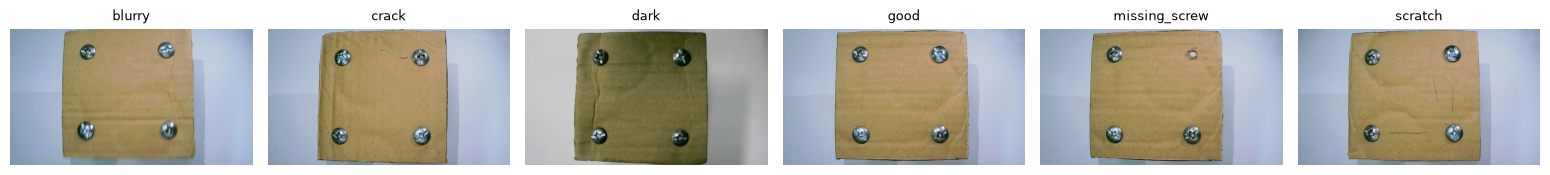

In [4]:
def grid(paths, titles, cols=6, size=2.6):
    rows_ = -(-len(paths) // cols)
    fig, axes = plt.subplots(rows_, cols, figsize=(cols * size, rows_ * size * 0.75))
    for ax in np.ravel(axes):
        ax.axis('off')
    for ax, p, t in zip(np.ravel(axes), paths, titles):
        ax.imshow(Image.open(p) if not isinstance(p, Image.Image) else p)
        ax.set_title(t, fontsize=9)
    plt.tight_layout(); plt.show()

real_train = list_images(Path('data/real/train'))
real_test = list_images(Path('data/real/test'))
examples = {label_of(p): p for p in real_train}
grid(list(examples.values()), list(examples), cols=6)

## 3. Baseline 1: a trained classifier (classic ML)

The usual approach: shrink each image to 64×64, normalise brightness, train logistic regression on the
training set, predict the label of each test image. Fast, but it learns whole-image patterns from
very few examples and cannot say *where* or *why*.

In [5]:
def evaluate(method, images):
    out = []
    for p in images:
        r = method.predict(p)
        out.append({'image': p.name, 'label': label_of(p), 'expected': expected_decision(label_of(p)).value,
                    'decision': r['decision'], 'reason': r['reason'], 'latency_s': 0.0})
    return out

def summary(rows, title):
    s = metrics(rows)
    f = lambda k: f"{100 * s[k][0] / s[k][1]:.0f}% ({s[k][0]}/{s[k][1]})" if s[k][1] else '-'
    return {'method': title, 'accuracy': f('accuracy'), 'escaped defects ↓': f('escaped'),
            'good falsely rejected ↓': f('false_reject'), 'sent to review': f('review')}

live = {}
for name in ['synthetic', 'real']:
    clf = TrainedClassifier().fit(list_images(Path('data', name, 'train')))
    live[name] = evaluate(clf, list_images(Path('data', name, 'test')))
pd.DataFrame([summary(live['real'], 'trained classifier, real test (live)'),
              summary(live['synthetic'], 'trained classifier, synthetic test (live, all 100)')])

,method,accuracy,escaped defects ↓,good falsely rejected ↓,sent to review
0,"trained classifier, real test (live)",77% (20/26),6% (1/16),50% (4/8),4% (1/26)
1,"trained classifier, synthetic test (live, all 100)",65% (65/100),27% (20/75),60% (15/25),0% (0/100)


In [6]:
pd.crosstab(pd.Series([r['label'] for r in live['real']], name='true label'),
            pd.Series([r['decision'] for r in live['real']], name='decision'))

decision,PASS,REJECT,REVIEW
true label,,,
blurry,0,1,0
crack,0,4,0
dark,0,0,1
good,4,4,0
missing_screw,1,7,0
scratch,0,4,0


## 4. Our deterministic layer, live

### 4a. Image-quality gate
Brightness and sharpness (variance of the Laplacian) are measured before the AI sees anything.
Limits for the real camera come from the training set: the midpoint between the one dark / one blurry
training photo and the dimmest / least sharp normal training photo.

In [7]:
cfg_real = replace(CellConfig(), **PART_QUALITY['cardboard_board'])
print('limits:', PART_QUALITY['cardboard_board'])
gate = []
for p in real_test:
    q = measure(p)
    gate.append({'image': p.name, 'brightness': round(q.brightness), 'sharpness': round(q.sharpness),
                 'gate says': problem(q, cfg_real) or 'ok'})
gate = pd.DataFrame(gate)
gate[(gate['gate says'] != 'ok') | gate.image.str.startswith(('dark', 'blurry'))]

limits: {'min_brightness': 142.0, 'min_sharpness': 230.0}


,image,brightness,sharpness,gate says
0,blurry_02.jpg,157,201,image too blurry (sharpness 201 < 230)
5,dark_02.jpg,151,127,image too blurry (sharpness 127 < 230)
23,scratch_03.jpg,160,177,image too blurry (sharpness 177 < 230)


Both unusable test photos go to a human (the dark one is caught by its low sharpness: dim light also blurs). It also wrongly calls one sharp scratch photo blurry (its limit came from a single blurry example), which sends that board to a human: safe, but a cost.

### 4b. Alignment and screw presence check
Boards are placed by hand, so screws move ~40 px between photos. `locate()` finds each screw inside a
search window (peak of local contrast) and re-centres the crop. Then three measurements per crop
(centre/ring brightness, centre edge detail, centre colour) feed a logistic regression **fitted on the
14 training photos only**. At run time it's a fixed formula: `SCREW`, `EMPTY`, or `UNSURE` (never passed).

In [8]:
spec = SPECS['cardboard_board']
presence = calibrate(real_train, spec, label_of)
print(f'calibrated on {presence.n_train_crops} training crops, train accuracy {presence.train_accuracy:.0%}')
print('weights', np.round(presence.weights, 2), 'bias', round(presence.bias, 2))

checks = []
for p in real_test:
    for r in locate(p, spec):
        if r.kind == 'screw':
            state, prob = presence.check(p, r)
            checks.append({'image': p.name, 'label': label_of(p), 'screw': r.name, 'state': state,
                           'p_screw': round(prob, 2), 'region': r})
checks = pd.DataFrame(checks)
missing = checks[checks.label == 'missing_screw']
others = checks[checks.label != 'missing_screw']
per_photo = missing.groupby('image').state.apply(lambda s: (s == 'EMPTY').sum())
print(f'missing-screw photos with exactly one EMPTY found: {(per_photo == 1).sum()}/{len(per_photo)}')
print(f'real screws wrongly called EMPTY: {(others.state == "EMPTY").sum()}/{len(others)} '
      f'(UNSURE, sent to a human: {(others.state == "UNSURE").sum()})')

calibrated on 32 training crops, train accuracy 100%
weights [ 0.25  1.92 -1.11] bias 2.38


missing-screw photos with exactly one EMPTY found: 8/8
real screws wrongly called EMPTY: 0/72 (UNSURE, sent to a human: 7)


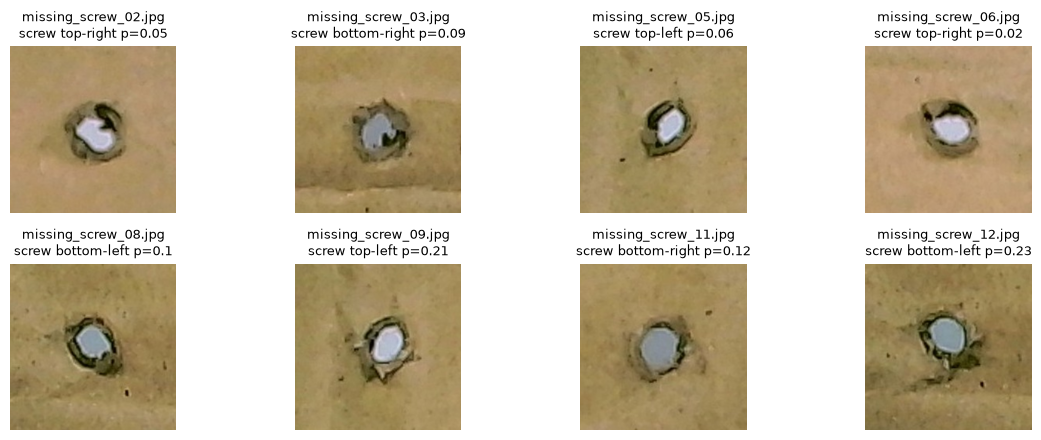

In [9]:
empties = missing[missing.state == 'EMPTY']
crops = [Image.open(__import__('io').BytesIO(crop(PROJECT / 'data/real/test' / r.image, r.region))) for r in empties.itertuples()]
grid(crops, [f"{r.image}\n{r.screw} p={r.p_screw}" for r in empties.itertuples()], cols=4, size=3)

Every crop the check called EMPTY is an empty hole, at the corner where the screw was removed. This takes ~0.1 s per board and needs no AI.

### 4c. The validator: the AI must answer in a checkable form
Gemma is asked to *describe first, then* end with `ANSWER: <one allowed word>`. Anything else
(rambling, a missing ANSWER line, a word outside the allowed set) is refused and the board goes to a human.

In [10]:
region = next(r for r in spec if r.kind == 'surface')
for raw in ['The cardboard shows a sharp dark zig-zag line.\nANSWER: DAMAGED',
            'Looks fine to me!',
            'ANSWER: CLEAN',
            'Plain cardboard with a soft fold.\nANSWER: PROBABLY_OK']:
    try:
        r = parse_region_answer(raw, region)
        print(f'accepted  -> {r.answer:8s} | {raw!r}')
    except ValidationError as e:
        print(f'REFUSED   -> {e} | {raw!r}')

accepted  -> DAMAGED  | 'The cardboard shows a sharp dark zig-zag line.\nANSWER: DAMAGED'
REFUSED   -> AI answer for surface top has no ANSWER line | 'Looks fine to me!'
REFUSED   -> AI gave no description for surface top | 'ANSWER: CLEAN'
REFUSED   -> AI answered 'PROBABLY' for surface top, expected one of ('CLEAN', 'DAMAGED') | 'Plain cardboard with a soft fold.\nANSWER: PROBABLY_OK'


## 5. The behaviour tree: every path, including failures

The tree below runs the line. To show each path quickly we plug in a **stand-in model** (`MockVLM`) that
reads its answer from the file name. It's not an inspector: it exercises the e-stop, the quality gate,
garbage AI output, AI timeouts and the circuit breaker. The real Gemma results are in section 6.

In [11]:
runtime = PROJECT / 'runtime_demo'
shutil.rmtree(runtime, ignore_errors=True)
demo = InspectionCell(replace(CellConfig(), runtime_dir=str(runtime)), runtime,
                      calibrate(list_images(Path('data/synthetic/train')), SPECS['synthetic_plate'], label_of), SPECS['synthetic_plate'], mock=True)
print(py_trees.display.unicode_tree(demo.tree.root))

{-} Inspection cycle
    --> E-stop clear?
    --> Acquire part
    {o} Classify
        {-} AI path
            --> Image quality OK?
            --> Locate screws
            --> Screw presence check
            --> Model healthy?
            --> Inspect regions with VLM
            --> Apply decision rules
        --> Route to human review
    --> E-stop clear? (pre-actuation)
    --> Actuate diverter



In [12]:
rows = []
for p in sorted(Path('samples').glob('*.png')):
    r = demo.predict(p)
    rows.append({'image': p.name, 'decision': r['decision'], 'path through the tree': ' → '.join(demo.cell.part.trace[2:]),
                 'reason': r['reason']})
pd.DataFrame(rows)

,image,decision,path through the tree,reason
0,blurry_01.png,REVIEW,Route to human review → E-stop clear? (pre-actuation) → Actuate diverter,image too blurry (sharpness 0 < 30)
1,crack_01.png,REJECT,Locate screws → Screw presence check → Model healthy? → Inspect regions with VLM → Apply decision rules → E-stop cle...,"surface damage at surface center: AI saw ""I see a defect here."""
2,dark_01.png,REVIEW,Route to human review → E-stop clear? (pre-actuation) → Actuate diverter,image too dark (brightness 21 < 40)
3,garbage_01.png,REVIEW,Locate screws → Screw presence check → Model healthy? → Inspect regions with VLM → Route to human review → E-stop cl...,AI answer rejected: AI answer for screw top-left has no ANSWER line
4,good_01.png,PASS,Locate screws → Screw presence check → Model healthy? → Inspect regions with VLM → Apply decision rules → E-stop cle...,all 9 regions checked and OK (screws confirmed by both checks)
5,good_02.png,PASS,Locate screws → Screw presence check → Model healthy? → Inspect regions with VLM → Apply decision rules → E-stop cle...,all 9 regions checked and OK (screws confirmed by both checks)
6,missing_screw_01.png,REJECT,Locate screws → Screw presence check → Model healthy? → Inspect regions with VLM → Apply decision rules → E-stop cle...,missing screw at screw top-right: presence check found an empty hole (p_screw 0.02)
7,missing_screw_02.png,REJECT,Locate screws → Screw presence check → Model healthy? → Inspect regions with VLM → Apply decision rules → E-stop cle...,missing screw at screw bottom-right: presence check found an empty hole (p_screw 0.02)
8,timeout_01.png,REVIEW,Locate screws → Screw presence check → Model healthy? → Inspect regions with VLM → Route to human review → E-stop cl...,AI unavailable: model did not answer (simulated timeout)


In [13]:
# E-stop: an operator (or the dashboard) creates runtime/ESTOP. The tree halts before the next part.
demo.cell.estop_file.parent.mkdir(parents=True, exist_ok=True)
demo.cell.estop_file.touch()
demo.source.next = Path('samples/good_01.png'); demo.cell.part = None
demo.tree.tick()
print('line stopped:', demo.cell.stopped, '| part inspected:', demo.cell.part)
demo.cell.estop_file.unlink()

line stopped: operator e-stop engaged | part inspected: None


## 6. Results: baselines vs our cell on the held-out test sets

Gemma 3 4B (Ollama, laptop CPU, temperature 0) predictions recorded by `experiment.py`. Both Gemma
methods were run on the same test images.

- **Baseline 2, naive Gemma:** one question about the whole image; the model reports a defect and a
  confidence; we trust the confidence (pass ≥ 0.85, reject ≥ 0.70).
- **Ours:** the behaviour tree above, with the real Gemma.

**Escaped defects** (a defect decided PASS) matters most: those parts ship.

In [14]:
def results_table(path, extra=None):
    rows = load(path)
    by = {m: [r for r in rows if r['method'] == m] for m in METHOD_TITLES}
    by = {m: v for m, v in by.items() if v}
    shared = set.intersection(*(set(r['image'] for r in v) for v in by.values()))
    out = []
    for m, v in by.items():
        v = [r for r in v if r['image'] in shared]
        out.append({**summary(v, METHOD_TITLES[m]),
                    'time / part (CPU)': f"{np.mean([r['latency_s'] for r in v]):.1f} s"})
    return pd.DataFrame(out), len(shared)

for name in ['real', 'synthetic']:
    table, n = results_table(Path('results', name, 'predictions.jsonl'))
    display(Markdown(f'### {name.capitalize()} test set (n = {n} images every method saw)'))
    display(table)

### Real test set (n = 26 images every method saw)

,method,accuracy,escaped defects ↓,good falsely rejected ↓,sent to review,time / part (CPU)
0,Baseline 1: trained classifier,77% (20/26),6% (1/16),50% (4/8),4% (1/26),0.0 s
1,Baseline 2: naive Gemma (whole image),46% (12/26),75% (12/16),0% (0/8),0% (0/26),17.8 s
2,Ours: inspection cell,85% (22/26),0% (0/16),38% (3/8),12% (3/26),72.6 s


### Synthetic test set (n = 40 images every method saw)

,method,accuracy,escaped defects ↓,good falsely rejected ↓,sent to review,time / part (CPU)
0,Baseline 1: trained classifier,65% (26/40),33% (10/30),40% (4/10),0% (0/40),0.0 s
1,Baseline 2: naive Gemma (whole image),25% (10/40),100% (30/30),0% (0/10),0% (0/40),17.8 s
2,Ours: inspection cell,95% (38/40),0% (0/30),20% (2/10),0% (0/40),86.9 s


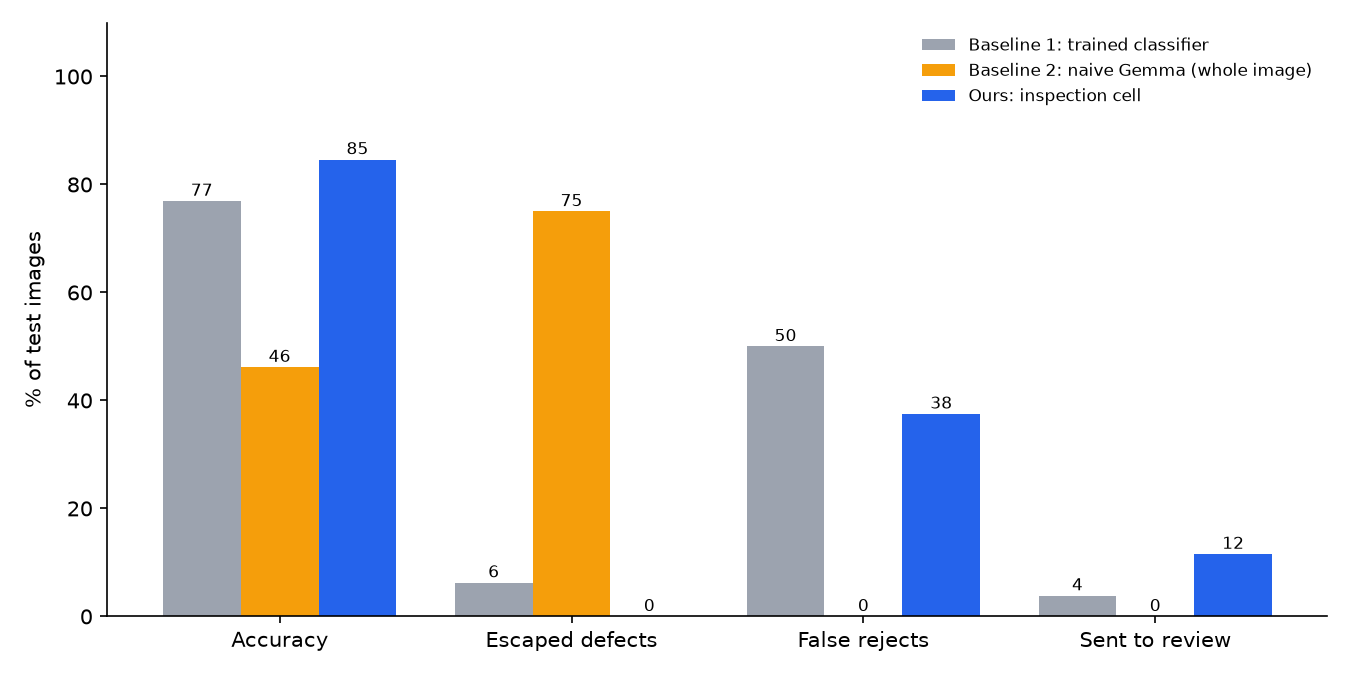

In [15]:
display(ShowImage('results/real/comparison.png', width=800))

### Real photos: decisions by true label
The naive model passes every missing screw and every scratch at "0.95 confidence". Our cell lets no defect through.

In [16]:
real_rows = load(Path('results/real/predictions.jsonl'))
for m in ['naive_vlm', 'inspection_cell']:
    v = [r for r in real_rows if r['method'] == m]
    display(Markdown(f'**{METHOD_TITLES[m]}**'))
    display(pd.crosstab(pd.Series([r['label'] for r in v], name='true label'),
                        pd.Series([r['decision'] for r in v], name='decision')))

**Baseline 2: naive Gemma (whole image)**

decision,PASS,REJECT
true label,,
blurry,1,0
crack,0,4
dark,1,0
good,8,0
missing_screw,8,0
scratch,4,0


**Ours: inspection cell**

decision,PASS,REJECT,REVIEW
true label,,,
blurry,0,0,1
crack,0,4,0
dark,0,0,1
good,5,3,0
missing_screw,0,8,0
scratch,0,3,1


In [17]:
naive = {r['image']: r['reason'] for r in real_rows if r['method'] == 'naive_vlm'}
ours = {r['image']: r for r in real_rows if r['method'] == 'inspection_cell'}
pick = ['missing_screw_02', 'missing_screw_05', 'scratch_02', 'crack_02', 'good_02']
pd.DataFrame([{'image': Path(i).name, 'naive Gemma said': naive[i][:110], 'our cell': f"{ours[i]['decision']}: {ours[i]['reason'][:110]}"}
              for i in sorted(ours) if Path(i).stem in pick])

,image,naive Gemma said,our cell
0,crack_02.jpg,crack @ 0.70: There is a visible crack in the cardboard backing.,"REJECT: surface damage at surface left: AI saw ""Yes, I see a distinct, sharp, dark zig-zag line."""
1,good_02.jpg,none @ 0.95: The part appears complete with all screws securely fastened and no visible defects.,PASS: all 9 regions checked and OK (screws confirmed by both checks)
2,missing_screw_02.jpg,none @ 0.95: The part appears to be complete with all screws in place and no visible defects.,REJECT: missing screw at screw top-right: presence check found an empty hole (p_screw 0.05)
3,missing_screw_05.jpg,none @ 0.95: The part appears to be complete with all screws securely fastened and without visible defects.,REJECT: missing screw at screw top-left: presence check found an empty hole (p_screw 0.06)
4,scratch_02.jpg,none @ 0.95: The part appears to be complete and undamaged with all screws securely fastened.,"REJECT: surface damage at surface bottom: AI saw ""Yes, I see a distinct, sharp dark line."""


### Is it right for the right reason?
For each surface rejection we draw the tile Gemma flagged (red). 6 of 7 flags sit on the drawn crack or
scratch. The 3 good boards it rejected were all flagged in the left tile, which contains a real fold crease
in the cardboard: a genuinely sharp line.

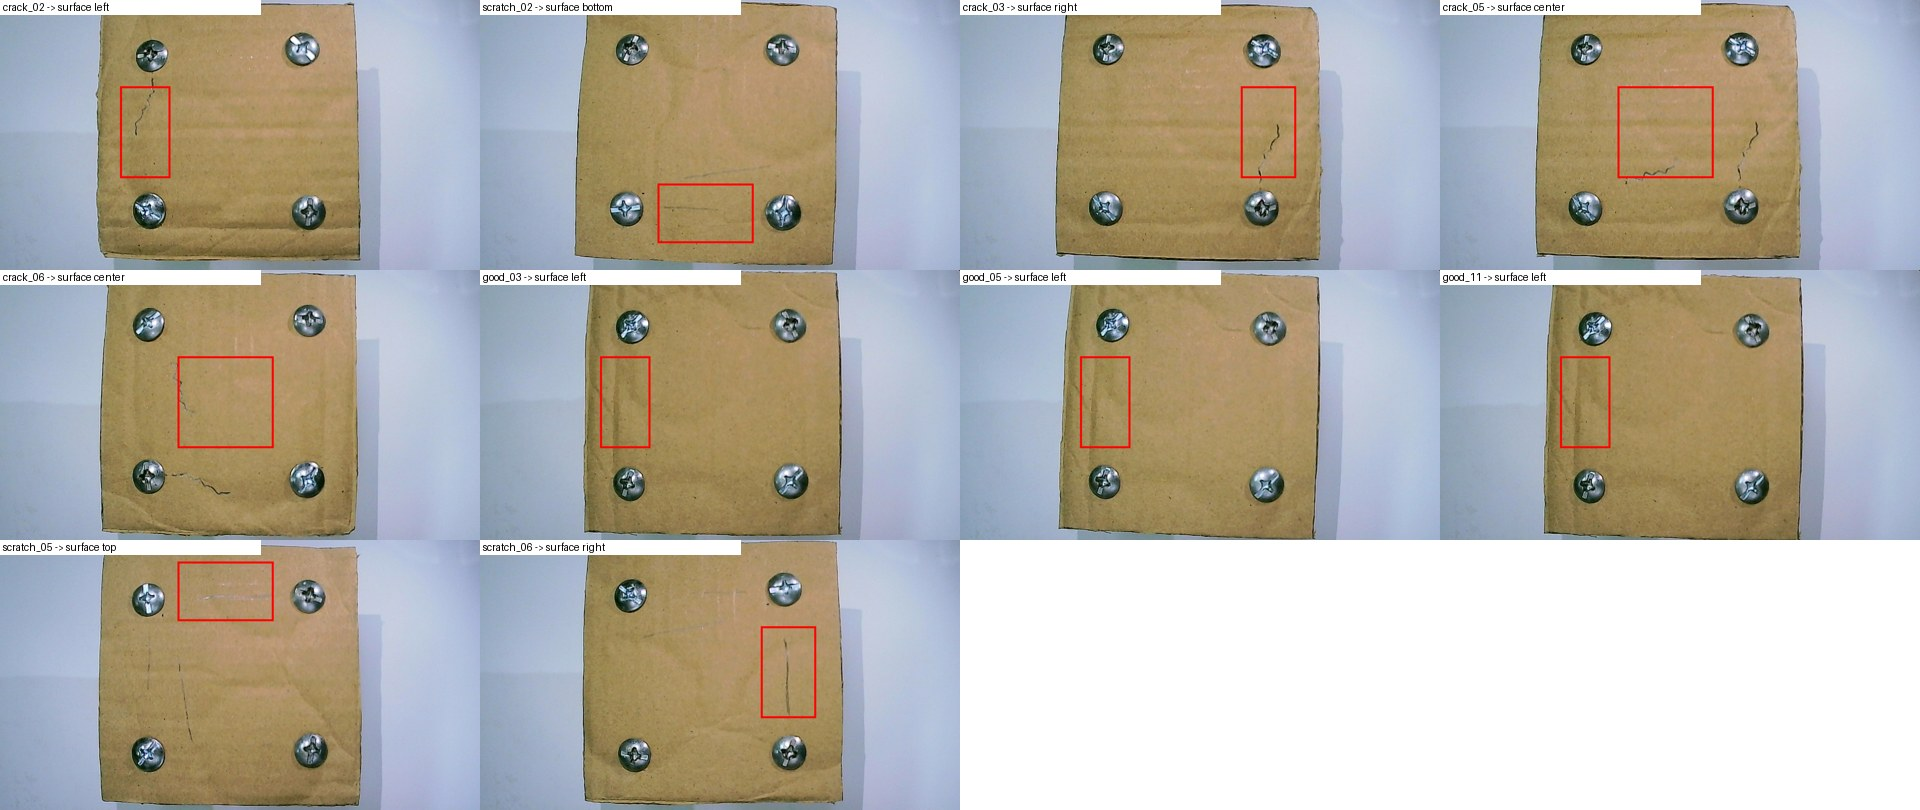

In [18]:
display(ShowImage('results/real/flagged_regions.jpg', width=900))

### How we got here: v1 → v2 (real photos)
v1 reused the surface prompt written for metal plates. On good boards Gemma described "a metal plate with
numerous small scratches and wear" and rejected all 8. v2 gives the cardboard its own prompt (part of the
part spec, like screw positions), chosen on the 14 training photos; the test set was then run once.
Note: **0 defects escaped in both versions.** When the AI component failed, the safety design turned it
into over-rejection, not shipped defects.

In [19]:
v = {'v1 (metal-plate prompt)': Path('results/real/v1/predictions.jsonl'), 'v2 (cardboard prompt)': Path('results/real/predictions.jsonl')}
pd.DataFrame([summary([r for r in load(p) if r['method'] == 'inspection_cell'], f'ours {k}') for k, p in v.items()])

,method,accuracy,escaped defects ↓,good falsely rejected ↓,sent to review
0,ours v1 (metal-plate prompt),65% (17/26),0% (0/16),100% (8/8),12% (3/26)
1,ours v2 (cardboard prompt),85% (22/26),0% (0/16),38% (3/8),12% (3/26)


## 7. Optional: run Gemma live on this machine
Set `RUN_LIVE_GEMMA = True` (a GPU and internet make this much faster; the first run downloads the
3.3 GB model). It runs our cell with the real Gemma on a few real test photos. Off by default so the
notebook runs in seconds.

In [20]:
RUN_LIVE_GEMMA = False
LIVE_IMAGES = ['missing_screw_02.jpg', 'crack_02.jpg', 'good_02.jpg']

def ollama_up():
    import requests
    try:
        return requests.get('http://localhost:11434/api/tags', timeout=2).ok
    except requests.RequestException:
        return False

if RUN_LIVE_GEMMA:
    import time
    if not ollama_up():
        if not shutil.which('ollama'):
            subprocess.run('curl -fsSL https://ollama.com/install.sh | sh', shell=True, check=True)
        subprocess.Popen(['ollama', 'serve'], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        while not ollama_up():
            time.sleep(1)
    subprocess.run(['ollama', 'pull', CellConfig.model], check=True)
    cell = InspectionCell(cfg_real, PROJECT / 'runtime_live', presence, spec)
    for name in LIVE_IMAGES:
        t0 = time.time()
        r = cell.predict(Path('data/real/test', name))
        print(f"{name:22s} {r['decision']:7s} {time.time() - t0:5.1f}s  {r['reason']}")

## 8. Conclusions

1. **Naive use of a small VLM is dangerous:** on real photos it shipped 12 of 16 defects, at high confidence.
2. **Deterministic checks carry what must never fail:** alignment + presence check found every missing
   screw in 0.1 s, calibrated from 14 photos.
3. **The AI is useful for the open-ended question** (is this a crack?) once the question is written for
   the material, and it explains itself in words an operator can read.
4. **The safety design held in every version:** 0 escaped defects; errors were over-rejections and
   human reviews, never shipped defects.
5. **Prompts are part of the specification** and must be validated per material, like any inspection parameter.

**Limitations (honest):** small data (26 real test photos; one error moves a rate 4–12 points); drawn,
not real, defects; quality-gate limits from one example each; ~2.5 min per good board on a laptop CPU
(9 Gemma calls; missing screws take 0.1 s); one camera, fixed jig; misalignment is not checked.

**Run it yourself:** `python run.py --source data/real/test --part cardboard_board --presence models/presence_cardboard.json`
and `streamlit run dashboard.py` for the operator dashboard (overrides, e-stop, review queue, audit trail).